In [4]:
import h2py
from h2py.utils import timestamp
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import pickle


mpl.rc("xtick", labelsize=7)
mpl.rc("ytick", labelsize=7)
mpl.rc("font", size=8)
mpl.rc("axes", labelsize=8)
mpl.rc("axes", titlesize=8)
mpl.rc("legend", fontsize=7)
mpl.rc("axes", titlesize="small")

In [7]:
naive_files = [f"../../simulations/mutation_weighting_demo/trials/unif_rep_{i}_naive_stats.pkl" for i in range(5)]
adjust_files = [f"../../simulations/mutation_weighting_demo/trials/unif_rep_{i}_weighted_stats.pkl" for i in range(5)]
pops = ["Altai", "Vindija", "Chagyrskaya", "Denisova", "Stuttgart", "Loschbour", "UstIshim", "Yoruba1"]

naive_data = []
adjust_data = []

for fname in naive_files:
    with open(fname, "rb") as fin:
        d = pickle.load(fin)
        d["pops"] = d["pop_ids"]
        d["bins"] = h2py.parsing._get_bin_tuples(d["bins"])
        d = h2py.parsing.subset_data(d, to_pops=pops)
        naive_data.append(d)

for fname in adjust_files:
    with open(fname, "rb") as fin:
        d = pickle.load(fin)
        d["pops"] = d["pop_ids"]
        d["bins"] = h2py.parsing._get_bin_tuples(d["bins"])
        d = h2py.parsing.subset_data(d, to_pops=pops)
        adjust_data.append(d)


data = naive_data[0]
graph = "bherer_full.yaml"
model = h2py.H2stats.from_demes(graph, u=1.3e-8, r_bins=data["bins"], sampled_demes=pops)

stats = h2py.utils._h2_names(8)
p1s = [int(x.split("_")[1]) for x in stats]
p2s = [int(x.split("_")[2]) for x in stats]
stats = []
for p1, p2 in zip(p1s, p2s):
    if p1 == p2:
        stats.append(pops[p1][:3])
    else:
        stats.append(f"{pops[p1][:3]}, {pops[p2][:3]}")

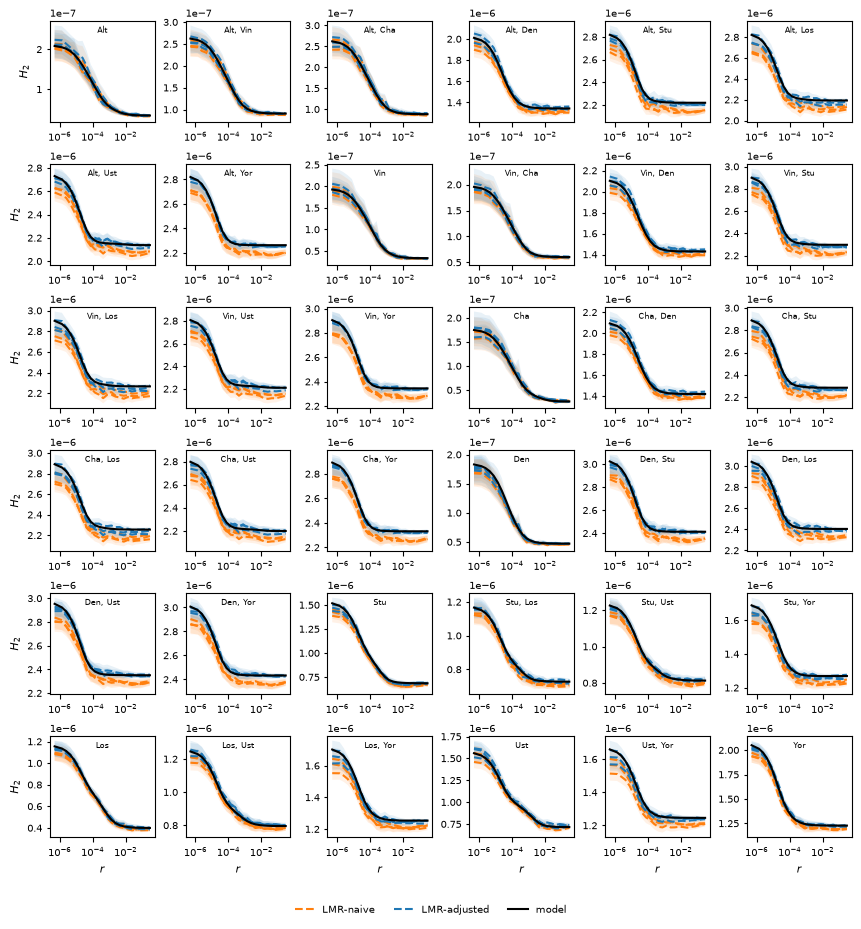

In [8]:
x = h2py.plotting.plot_h2_curves(
    h2_stats=[model],
    means=[d["means"] for d in naive_data[:3]] + [d["means"] for d in adjust_data[:3]],
    varcovs=[d["varcovs"] for d in naive_data[:3]] + [d["varcovs"] for d in adjust_data[:3]],
    stats=stats,
    fig_size=(8.5, 8.75),
    pops=pops,
    rows=6,
    cols=6,
    r_bins=data["bins"],
    colors=["tab:orange"] * 3 + ["tab:blue"] * 3 + ["black"],
    data_labels=["LMR-naive", "LMR-adjusted"],
    model_labels=["model"],
    out_file="../../figures/sim_lmr_adjust.pdf",
    alpha=0.1
)